# Обнаружение повторного JPEG-сжатия
Многослойный персептрон (MLP) с dropout 20 % и одномерная свёрточная сеть (CNN) получают одни и те же признаки. Сети обучаются с нуля на готовых метках DJPEG. По валидационной потере выбираются эпоха, запуск и модель для программы. Тест DJPEG, фотографии UCID и измерение времени используются после этого выбора.

Перед первым запуском нужно подготовить данные по инструкции в README. Ячейки выполняются сверху вниз на Mac с поддержкой MPS.

In [1]:
import hashlib
import json
import platform
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

from detector import classify, load_detector, make_model

device = torch.device("mps")
assert torch.backends.mps.is_available(), "Для этого опыта требуется GPU Apple с поддержкой MPS"
torch.set_num_threads(1)
out = Path("research")
archive = Path("archive/20-epochs")
weights = Path("weights/60-epochs")
out.mkdir(exist_ok=True)
weights.mkdir(parents=True, exist_ok=True)
chip = subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], text=True).strip()
print(chip, "· macOS", platform.mac_ver()[0], "· PyTorch", torch.__version__, "·", device)

Apple M4 Pro · macOS 26.5 · PyTorch 2.15.0 · mps


## Данные и разбиение
Обе версии одного фрагмента относятся к одной выборке. Соседние номера фрагментов объединены в группы по 1000. Группы распределены до отбора примеров. Внутри одного набора фотография может дать несколько фрагментов. Авторский архив позволяет установить номер фрагмента, тогда как номер исходной фотографии неизвестен.

In [2]:
files = pd.read_csv("data/manifest.csv")
X = np.load("data/djpeg-features.npy")
assert X.shape == (len(files), 1171) and np.isfinite(X).all()
assert np.allclose(X[:, :1107].reshape(-1, 9, 123).sum(2), 1)
assert files.groupby("block").label.agg(list).apply(lambda a: a == [0, 1]).all()
assert files.groupby((files.block - 1) // 1000).split.nunique().max() == 1
assert files.groupby("pixel_sha256").split.nunique().max() == 1
parts = {p: files.index[files.split == p].to_numpy() for p in ("train", "val", "test")}
counts = pd.crosstab(files.split, files.label).reindex(parts)
display(counts.rename(columns={0: "однократное", 1: "двукратное"}))
manifest_hash = hashlib.sha256(Path("data/manifest.csv").read_bytes()).hexdigest()
files.to_csv(out / "manifest.csv.gz", index=False, compression={"method": "gzip", "mtime": 0})
assert manifest_hash == json.loads((archive / "research/context.json").read_text())["manifest_sha256"]
paired = files.pivot(index="block", columns="label", values="first_table")
print("SHA-256 манифеста:", manifest_hash)
print("Совпадение первой таблицы у пар:", (paired[0] == paired[1]).mean())
print("Одинаковые декодированные изображения с разными метками:",
      (files.groupby("pixel_sha256").label.nunique() == 2).sum())

label,однократное,двукратное
split,,
train,15000,15000
val,2500,2500
test,2500,2500


SHA-256 манифеста: 54699e6c9a82400fae925708cda2d735d7b23650a31fd3947b07b65687d1cd45
Совпадение первой таблицы у пар: 1.0
Одинаковые декодированные изображения с разными метками: 571


In [3]:
# Контроль соответствия сцен в 200 парах по уменьшенному изображению.
def thumbnail(path):
    with Image.open(path) as image:
        return np.asarray(image.convert("L").resize((16, 16), Image.Resampling.BOX), dtype=float)

sample = files.loc[parts["train"][:400]]
single = np.stack([thumbnail(p) for p in sample.loc[sample.label == 0, "path"]])
double = np.stack([thumbnail(p) for p in sample.loc[sample.label == 1, "path"]])
pair_mae = float(np.mean(np.abs(single - double)))
shuffle_mae = float(np.mean(np.abs(single - np.roll(double, 1, axis=0))))
print(f"Среднее различие яркости, уровней из 255: пары {pair_mae:.2f}, переставленные пары {shuffle_mae:.2f}")

Среднее различие яркости, уровней из 255: пары 0.11, переставленные пары 72.57


## Обучение на GPU
Каждый вход содержит девять гистограмм ДКП и 64 шага квантования. Среднее и стандартное отклонение вычисляются по обучающей части. Нижняя граница масштаба равна одному отсчёту гистограммы (1/1024). Обе сети используют Adam с шагом 0,001, размер пакета 256 и общий предел в 60 эпох. Остановка наступает после пяти эпох без уменьшения валидационной кросс-энтропии. В MLP после каждой из двух скрытых активаций при обучении применяется dropout с вероятностью 0,2. При валидации и классификации dropout отключён. У CNN два свёрточных слоя на 16 и 32 канала.

In [4]:
Xtrain = X[parts["train"]]
mean = torch.from_numpy(Xtrain.mean(axis=0, dtype=np.float64).astype("float32"))
scale = torch.from_numpy(Xtrain.std(axis=0, dtype=np.float64).clip(min=1 / 1024).astype("float32"))
del Xtrain
y = files.label.to_numpy(dtype="int64")

def inputs(indices):
    return ((torch.from_numpy(X[indices]) - mean) / scale).to(device), torch.from_numpy(y[indices]).to(device)

train_x, train_y = inputs(parts["train"])
val_x, val_y = inputs(parts["val"])
loss_fn = torch.nn.CrossEntropyLoss()

def fit(name, seed, x, labels, vx, vy, limit, dropout=0.0, channels=(16, 32)):
    torch.manual_seed(seed)
    model = make_model(name, dropout=dropout, channels=channels).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    rng = np.random.default_rng(seed)
    best_loss, best_epoch, best_state = float("inf"), 0, None
    history = []
    torch.mps.synchronize()
    start = time.perf_counter()
    for epoch in range(1, limit + 1):
        model.train()
        order = torch.from_numpy(rng.permutation(len(x))).to(device)
        total = torch.zeros((), device=device)
        for batch in order.split(256):
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(x[batch]), labels[batch])
            loss.backward()
            optimizer.step()
            total += loss.detach() * len(batch)
        model.eval()
        with torch.inference_mode():
            logits = torch.cat([model(batch) for batch in vx.split(512)])
            val_loss = loss_fn(logits, vy).item()
            acc = (logits.argmax(1) == vy).float().mean().item()
        history.append(dict(model=name, seed=seed, epoch=epoch, train_loss=total.item() / len(x),
                            val_loss=val_loss, val_accuracy=acc))
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if epoch - best_epoch >= 5:
            break
    torch.mps.synchronize()
    run = dict(model=name, seed=seed, epoch=best_epoch, epochs_run=epoch, epoch_limit=limit, dropout=dropout, val_loss=best_loss,
               val_accuracy=history[best_epoch - 1]["val_accuracy"], seconds=time.perf_counter() - start,
               parameters=sum(p.numel() for p in model.parameters()))
    return best_state, run, history

In [5]:
# Пробный запуск проверяет вычисления на MPS. Его веса не участвуют в сравнении.
_, pilot, pilot_epochs = fit("MLP", 7, train_x[:2000], train_y[:2000], val_x[:500], val_y[:500], 3, dropout=0.2)
display(pd.DataFrame(pilot_epochs).round(4))

,model,seed,epoch,train_loss,val_loss,val_accuracy
0,MLP,7,1,0.6781,0.6609,0.622
1,MLP,7,2,0.6430,0.6458,0.616
2,MLP,7,3,0.6028,0.6218,0.634


In [6]:
runs, epochs = [], []
seeds = (17, 29, 43)
limit = 60
for name, dropout in (("MLP", 0.2), ("CNN", 0.0)):
    for seed in seeds:
        state, run, history = fit(name, seed, train_x, train_y, val_x, val_y, limit, dropout=dropout)
        checkpoint = dict(model=name, dropout=dropout, state=state, mean=mean, scale=scale,
                          seed=seed, epoch=run["epoch"], epoch_limit=limit, val_loss=run["val_loss"],
                          manifest_sha256=manifest_hash)
        path = weights / f"{name}-{seed}.pt"
        torch.save(checkpoint, path.with_suffix(".tmp"))
        path.with_suffix(".tmp").replace(path)
        runs.append(run)
        epochs.extend(history)
        print(f"{name}, seed {seed}: эпоха {run['epoch']}, val loss {run['val_loss']:.4f}", flush=True)

runs = pd.DataFrame(runs)
runs.to_csv(out / "runs.csv", index=False)
pd.DataFrame(epochs).to_csv(out / "epochs.csv", index=False)
best = runs.sort_values(["val_loss", "seed"]).drop_duplicates("model").set_index("model")
choice = best.val_loss.idxmin()
choice_seed = int(best.loc[choice, "seed"])
choice_path = Path("weights/choice.json")
selected = weights / f"{choice}-{choice_seed}.pt"
settings = dict(file=selected.relative_to(choice_path.parent).as_posix(),
                criterion="minimum validation cross-entropy", manifest_sha256=manifest_hash)
choice_path.with_suffix(".tmp").write_text(json.dumps(settings, indent=2) + "\n")
choice_path.with_suffix(".tmp").replace(choice_path)
print("Для программы выбрана", choice, "с seed", choice_seed)
display(best.round(4))

MLP, seed 17: эпоха 13, val loss 0.4500


MLP, seed 29: эпоха 15, val loss 0.4497


MLP, seed 43: эпоха 9, val loss 0.4523


CNN, seed 17: эпоха 21, val loss 0.4307


CNN, seed 29: эпоха 21, val loss 0.4298


CNN, seed 43: эпоха 21, val loss 0.4290


Для программы выбрана CNN с seed 43


,seed,epoch,epochs_run,epoch_limit,dropout,val_loss,val_accuracy,seconds,parameters
model,,,,,,,,,
CNN,43,21,26,60,0.0,0.4290,0.8022,5.1573,35170
MLP,29,15,20,60,0.2,0.4497,0.7870,1.0866,77154


## Проверка числа эпох и ширины сети
В исходном опыте обе модели обучались до 20 эпох, MLP — без dropout. Для контроля ширины CNN число каналов увеличено с 16 и 32 до 32 и 64. Этот вариант оценивается только на валидации. В таблице приведены средние трёх запусков в лучшей по валидационной потере эпохе каждого запуска.

In [7]:
wide_runs = []
for seed in seeds:
    _, run, _ = fit("CNN", seed, train_x, train_y, val_x, val_y, limit, channels=(32, 64))
    wide_runs.append(run)
wide_runs = pd.DataFrame(wide_runs)
wide_runs.to_csv(out / "width-control.csv", index=False)

old_runs = pd.read_csv(archive / "research/runs.csv")
variants = [("MLP", 0.0, 20, old_runs.query("model == 'MLP'")),
            ("MLP", 0.2, limit, runs.query("model == 'MLP'")),
            ("CNN 16/32", 0.0, 20, old_runs.query("model == 'CNN'")),
            ("CNN 16/32", 0.0, limit, runs.query("model == 'CNN'")),
            ("CNN 32/64", 0.0, limit, wide_runs)]
validation = []
for variant, dropout, cap, frame in variants:
    validation.append(dict(variant=variant, dropout=dropout, epoch_limit=cap, runs=len(frame),
                           parameters=frame.parameters.iloc[0], val_loss=frame.val_loss.mean(),
                           val_accuracy=frame.val_accuracy.mean()))
validation = pd.DataFrame(validation)
validation.to_csv(out / "validation-comparison.csv", index=False)
display(validation.round(4))

,variant,dropout,epoch_limit,runs,parameters,val_loss,val_accuracy
0,MLP,0.0,20,3,77154,0.4611,0.7768
1,MLP,0.2,60,3,77154,0.4507,0.7815
2,CNN 16/32,0.0,20,3,35170,0.4315,0.7949
3,CNN 16/32,0.0,60,3,35170,0.4298,0.7993
4,CNN 32/64,0.0,60,3,71266,0.4297,0.8001


## Качество на отложенной части DJPEG
Положительный класс — двукратное сжатие, порог оценки — 0,5. Модели сравниваются на одних и тех же 5000 файлах. Для доверительного интервала разности accuracy у выбранных запусков повторно выбираются целые пары фрагментов.

In [8]:
def scores(data, detector):
    model, center, spread = detector
    with torch.inference_mode():
        batches = ((torch.from_numpy(batch) - center) / spread for batch in np.array_split(data, max(1, len(data) // 512)))
        return torch.cat([model(batch).softmax(1)[:, 1] for batch in batches]).numpy()

def metrics(truth, score):
    pred = score >= 0.5
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(truth, pred), precision=precision_score(truth, pred, zero_division=0),
                recall=recall_score(truth, pred, zero_division=0), f1=f1_score(truth, pred, zero_division=0),
                tn=tn, fp=fp, fn=fn, tp=tp)

test = parts["test"]
predictions = files.loc[test, ["path", "block", "label", "first_table", "final_table"]].reset_index(drop=True)
quality = []
detectors = {}
for row in runs.itertuples():
    key = f"{row.model}-{row.seed}"
    detector = load_detector(weights / f"{key}.pt")
    predictions[key] = scores(X[test], detector)
    quality.append(dict(model=row.model, seed=row.seed, **metrics(y[test], predictions[key])))
    if row.seed == best.loc[row.model, "seed"]:
        detectors[row.model] = detector
quality = pd.DataFrame(quality)
quality.to_csv(out / "test-metrics.csv", index=False)
predictions.to_csv(out / "test-predictions.csv.gz", index=False, float_format="%.8g")
display(quality.round(4))
display(quality.groupby("model")[["accuracy", "precision", "recall", "f1"]].agg(["mean", "std"]).round(4))

,model,seed,accuracy,precision,recall,f1,tn,fp,fn,tp
0,MLP,17,0.7922,0.8847,0.6720,0.7638,2281,219,820,1680
1,MLP,29,0.7916,0.8903,0.6652,0.7614,2295,205,837,1663
2,MLP,43,0.7802,0.8826,0.6464,0.7462,2285,215,884,1616
3,CNN,17,0.8138,0.9153,0.6916,0.7879,2340,160,771,1729
4,CNN,29,0.8006,0.8632,0.7144,0.7818,2217,283,714,1786
5,CNN,43,0.8066,0.9075,0.6828,0.7793,2326,174,793,1707


accuracy         precision          recall              f1        
          mean     std      mean     std    mean     std    mean     std
model                                                                   
CNN      0.807  0.0066    0.8953  0.0281  0.6963  0.0163  0.7830  0.0044
MLP      0.788  0.0068    0.8858  0.0040  0.6612  0.0133  0.7572  0.0095

In [9]:
from collections import Counter
# Контроль того, насколько сам выбор последней таблицы связан с меткой.
train_counts = [Counter(), Counter()]
for i in parts["train"]:
    train_counts[y[i]][X[i, -64:].tobytes()] += 1
table_only = [int(train_counts[1][X[i, -64:].tobytes()] > train_counts[0][X[i, -64:].tobytes()]) for i in test]
baseline = accuracy_score(y[test], table_only)
hits = {}
for name in detectors:
    pred = predictions[f"{name}-{int(best.loc[name, 'seed'])}"] >= .5
    hits[name] = (pred == y[test]).groupby(predictions.block).mean().to_numpy()
delta = hits["CNN"] - hits["MLP"]
def paired_interval(differences):
    rng = np.random.default_rng(2026)
    samples = [rng.choice(differences, size=len(differences), replace=True).mean() for _ in range(2000)]
    return np.quantile(samples, [.025, .975])

interval = paired_interval(delta)
print(f"Последняя таблица без изображения: {baseline:.2%}. Постоянный класс: 50,00 %.")
print(f"Accuracy CNN минус MLP: {delta.mean()*100:.2f} п. п., 95 % интервал по парам: {interval*100}.")

Последняя таблица без изображения: 51.22%. Постоянный класс: 50,00 %.
Accuracy CNN минус MLP: 1.50 п. п., 95 % интервал по парам: [0.58 2.36].


## Совпадения изображений и признаков
Две разные истории сохранения могут дать совершенно одинаковый файл. Кроме того, разные изображения иногда имеют один вектор гистограмм и таблицу квантования. Проверим, сколько таких случаев в тесте и меняется ли доля правильных ответов при исключении признаков, уже встречавшихся в обучении или валидации.

In [10]:
feature_hash = pd.Series([hashlib.sha256(row.tobytes()).digest() for row in X])
seen = feature_hash.iloc[np.r_[parts["train"], parts["val"]]]
fresh = ~feature_hash.iloc[test].isin(seen).to_numpy()
correct = (predictions[f"{choice}-{choice_seed}"].to_numpy() >= .5) == y[test]
test_files = files.iloc[test]
byte_pairs = test_files.pivot(index="block", columns="label", values="sha256")
pixel_pairs = test_files.pivot(index="block", columns="label", values="pixel_sha256")
double_train = files[(files.split == "train") & (files.label == 1)]
audit = dict(test_pairs_identical_bytes=int((byte_pairs[0] == byte_pairs[1]).sum()),
             test_pairs_identical_pixels=int((pixel_pairs[0] == pixel_pairs[1]).sum()),
             test_files_with_seen_features=int((~fresh).sum()), accuracy_fresh_features=float(correct[fresh].mean()),
             train_double_same_table_id=int((double_train.first_table == double_train.final_table).sum()))
(out / "sample-checks.json").write_text(json.dumps(audit, indent=2) + "\n")
print(f"Пары на тесте: совпали пиксели у {audit['test_pairs_identical_pixels']}, байты у {audit['test_pairs_identical_bytes']}.")
print(f"Ранее встречались признаки {sum(~fresh)} файлов. Accuracy на остальных {sum(fresh)}: {correct[fresh].mean():.2%}.")

Пары на тесте: совпали пиксели у 83, байты у 3.
Ранее встречались признаки 11 файлов. Accuracy на остальных 4989: 80.74%.


## Качество при разных параметрах JPEG
Для 300 отдельных TIFF-фотографий UCID известна история обоих сохранений. Внешний набор включает все сочетания Q1 и Q2 из {55, 65, 75, 85, 95}, два варианта цветовой субдискретизации и два положения сетки. Значение offset = 4 соответствует сдвигу на четыре пикселя по обеим осям. Положение сцены в конечном фрагменте одинаково. Один и тот же набор однократных JPEG служит контролем для разных Q1 и положений сетки.

In [11]:
external = pd.read_csv("data/ucid.csv")
external_x = np.load("data/ucid-features.npy")
assert external.photo.nunique() == 300 and len(external) == len(external_x) == 33000
assert not external.duplicated(["photo", "sampling", "offset", "label", "q1", "q2"]).any()
cells = []
for name, detector in detectors.items():
    external[name] = scores(external_x, detector)
    double = external[external.label == 1].copy()
    single = external[external.label == 0].copy()
    tpr = (double[name] >= .5).groupby([double[k] for k in ("sampling", "offset", "q1", "q2")]).mean().rename("tpr").reset_index()
    tnr = (single[name] < .5).groupby([single.sampling, single.q2]).mean().rename("tnr").reset_index()
    rates = tpr.merge(tnr, on=["sampling", "q2"], validate="many_to_one")
    rates["balanced_accuracy"] = (rates.tpr + rates.tnr) / 2
    rates["model"] = name
    rates["n_double"] = rates["n_single"] = 300
    cells.append(rates)
cells = pd.concat(cells, ignore_index=True)
cells["relation"] = np.select([cells.q1 < cells.q2, cells.q1 == cells.q2], ["Q1<Q2", "Q1=Q2"], default="Q1>Q2")
cells.to_csv(out / "compression.csv", index=False)
external.to_csv(out / "ucid-predictions.csv.gz", index=False, float_format="%.8g")
display(cells.groupby(["model", "sampling", "offset", "relation"])[["tpr", "tnr", "balanced_accuracy"]].mean().round(3))

tpr    tnr  balanced_accuracy
model sampling offset relation                                 
CNN   0        0      Q1<Q2     0.813  0.963              0.888
                      Q1=Q2     0.036  0.966              0.501
                      Q1>Q2     0.102  0.969              0.536
               4      Q1<Q2     0.034  0.963              0.499
                      Q1=Q2     0.030  0.966              0.498
                      Q1>Q2     0.031  0.969              0.500
      2        0      Q1<Q2     0.806  0.963              0.884
                      Q1=Q2     0.036  0.966              0.501
                      Q1>Q2     0.105  0.969              0.537
               4      Q1<Q2     0.035  0.963              0.499
                      Q1=Q2     0.028  0.966              0.497
                      Q1>Q2     0.033  0.969              0.501
MLP   0        0      Q1<Q2     0.766  0.989              0.877
                      Q1=Q2     0.010  0.989              0.500
                      Q1>Q2     0.046  0.990              0.518
               4      Q1<Q2     0.010  0.989              0.500
                      Q1=Q2     0.006  0.989              0.498
                      Q1>Q2     0.006  0.990              0.498
      2        0      Q1<Q2     0.754  0.989              0.871
                      Q1=Q2     0.011  0.989              0.500
                      Q1>Q2     0.046  0.990              0.518
               4      Q1<Q2     0.010  0.989              0.499
                      Q1=Q2     0.005  0.989              0.497
                      Q1>Q2     0.006  0.990              0.498

## Время обработки
Один поток PyTorch, одна модель в памяти, один файл за вызов. После 100 вызовов прогрева каждой сети обе модели обрабатывают одни и те же 1000 JPEG три раза. Для каждого файла порядок моделей чередуется, и в каждом проходе каждая сеть 500 раз вызывается первой. Файлы заранее читаются, чтобы обе модели работали с прогретым файловым кешем. Интервал охватывает открытие JPEG, декодирование, вычисление признаков, сеть и получение оценки класса.

Отдельное измерение воспроизводит запуск программы пользователем. Для каждого из 20 файлов каждая модель один раз вызывается в новом процессе Python. Время включает импорт библиотек, загрузку весов, обработку изображения и выход из программы.

In [12]:
import sys
rng = np.random.default_rng(1701)
paths = predictions.path.iloc[rng.permutation(len(predictions))[:1000]].tolist()
for path in paths:
    Path(path).read_bytes()
for detector in detectors.values():
    for path in paths[:100]:
        classify(path, detector)

timing = []
for repeat in range(3):
    for i, path in enumerate(rng.permutation(paths)):
        order = ("MLP", "CNN") if (repeat + i) % 2 == 0 else ("CNN", "MLP")
        for name in order:
            start = time.perf_counter_ns()
            classify(path, detectors[name])
            ms = (time.perf_counter_ns() - start) / 1e6
            timing.append((name, repeat + 1, path, ms))
timing = pd.DataFrame(timing, columns=["model", "repeat", "path", "ms"])
timing.to_csv(out / "timing.csv.gz", index=False)
speed = timing.groupby("model").ms.agg(median_ms="median", p95_ms=lambda s: s.quantile(.95))
speed.to_csv(out / "speed.csv")
display(speed.round(3))

starts = []
for i, path in enumerate(paths[:20]):
    for name in (("MLP", "CNN") if i % 2 == 0 else ("CNN", "MLP")):
        file = weights / f"{name}-{int(best.loc[name, 'seed'])}.pt"
        command = [sys.executable, "detector.py", path, "--weights", str(file)]
        start = time.perf_counter()
        subprocess.run(command, stdout=subprocess.DEVNULL, check=True)
        starts.append((name, path, time.perf_counter() - start))
starts = pd.DataFrame(starts, columns=["model", "path", "seconds"])
starts.to_csv(out / "cli-timing.csv", index=False)
display(starts.groupby("model").seconds.agg(median_s="median", p95_s=lambda s: s.quantile(.95)).round(3))

,median_ms,p95_ms
model,,
CNN,0.520,0.679
MLP,0.495,0.652


,median_s,p95_s
model,,
CNN,0.859,0.885
MLP,0.854,0.925


## Сопоставление с исходным экспериментом
Сравниваются веса, которые в каждом опыте выбраны по минимуму валидационной потери. Предсказания относятся к одним и тем же файлам DJPEG и вариантам снимков UCID. Медианы времени измерены отдельно для каждого опыта.

In [13]:
old_research = archive / "research"
old_test = pd.read_csv(old_research / "test-predictions.csv.gz")
old_ucid = pd.read_csv(old_research / "ucid-predictions.csv.gz")
assert old_test[["block", "path", "label"]].equals(predictions[["block", "path", "label"]])
ucid_keys = ["photo", "sampling", "offset", "label", "q1", "q2"]
assert old_ucid[ucid_keys].equals(external[ucid_keys])

comparison = []
for protocol, folder in [(20, old_research), (limit, out)]:
    training = pd.read_csv(folder / "runs.csv")
    selected_runs = training.sort_values(["val_loss", "seed"]).drop_duplicates("model")
    test_metrics = pd.read_csv(folder / "test-metrics.csv").set_index(["model", "seed"])
    ucid_cells = pd.read_csv(folder / "compression.csv")
    speed_stats = pd.read_csv(folder / "speed.csv").set_index("model")
    cli_stats = pd.read_csv(folder / "cli-timing.csv").groupby("model").seconds.median()
    for row in selected_runs.itertuples():
        test_row = test_metrics.loc[(row.model, row.seed)].to_dict()
        rates = ucid_cells[ucid_cells.model == row.model].groupby("offset").balanced_accuracy.mean()
        comparison.append(dict(epoch_limit=protocol, model=row.model, dropout=getattr(row, "dropout", 0.0),
                               seed=row.seed, epoch=row.epoch, val_loss=row.val_loss, **test_row,
                               ucid_ba_aligned=rates[0], ucid_ba_shift4=rates[4],
                               median_ms=speed_stats.loc[row.model, "median_ms"], cli_median_s=cli_stats[row.model]))
comparison = pd.DataFrame(comparison).sort_values(["model", "epoch_limit"])
comparison = comparison.astype({key: int for key in ["tn", "fp", "fn", "tp"]})
comparison.to_csv(out / "protocol-comparison.csv", index=False)
display(comparison.round(4))
changes = []
for name, rows in comparison.groupby("model"):
    old, new = rows.sort_values("epoch_limit").itertuples(index=False)
    old_correct = old_test[f"{name}-{old.seed}"].ge(0.5).eq(old_test.label)
    new_correct = predictions[f"{name}-{new.seed}"].ge(0.5).eq(predictions.label)
    change = (new_correct.astype(int) - old_correct.astype(int)).groupby(predictions.block).mean()
    low, high = paired_interval(change.to_numpy())
    changes.append(dict(model=name, accuracy_change=change.mean(), ci_low=low, ci_high=high,
                        extra_correct=int(new_correct.sum() - old_correct.sum()),
                        fp_change=new.fp - old.fp, fn_change=new.fn - old.fn))
changes = pd.DataFrame(changes)
changes.to_csv(out / "protocol-deltas.csv", index=False)
display(changes.round(4))

,epoch_limit,model,dropout,seed,epoch,val_loss,accuracy,precision,recall,f1,tn,fp,fn,tp,ucid_ba_aligned,ucid_ba_shift4,median_ms,cli_median_s
0,20,CNN,0.0,29,17,0.4309,0.8044,0.8879,0.6968,0.7808,2280,220,758,1742,0.6601,0.4994,0.5461,0.9073
2,60,CNN,0.0,43,21,0.4290,0.8066,0.9075,0.6828,0.7793,2326,174,793,1707,0.6692,0.4992,0.5198,0.8590
1,20,MLP,0.0,17,7,0.4573,0.7872,0.8485,0.6992,0.7667,2188,312,752,1748,0.6584,0.4993,0.5120,0.9170
3,60,MLP,0.2,29,15,0.4497,0.7916,0.8903,0.6652,0.7614,2295,205,837,1663,0.6568,0.4984,0.4951,0.8536


,model,accuracy_change,ci_low,ci_high,extra_correct,fp_change,fn_change
0,CNN,0.0022,-0.0056,0.0102,11,-46,35
1,MLP,0.0044,-0.0040,0.0124,22,-107,85


## Графики и параметры запуска

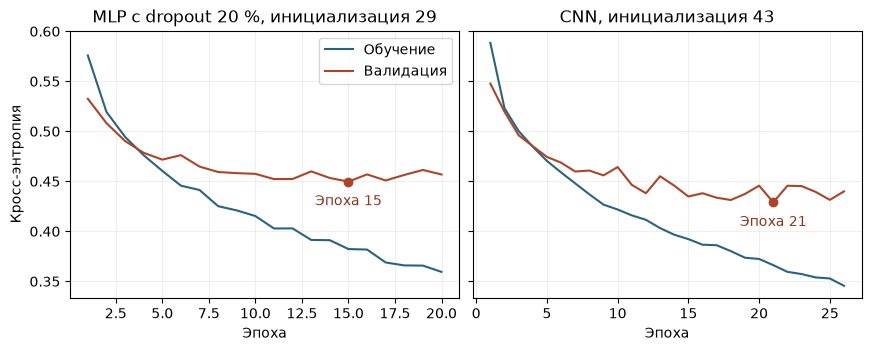

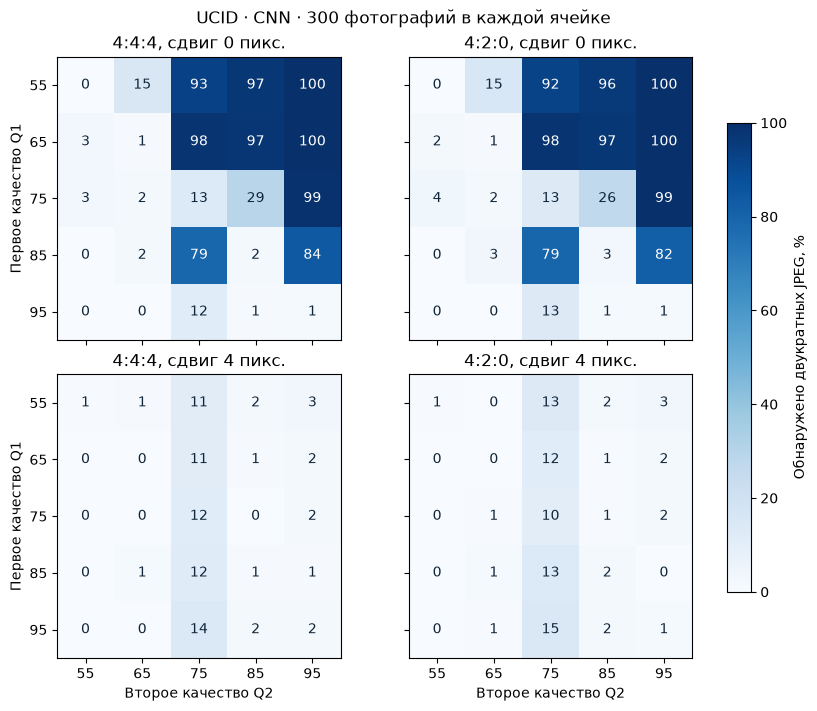

In [14]:
history = pd.DataFrame(epochs)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4), sharey=True, layout="constrained")
for ax, (name, subtitle) in zip(axes, [("MLP", "MLP с dropout 20 %"), ("CNN", "CNN")]):
    seed = int(best.loc[name, "seed"])
    curve = history[(history.model == name) & (history.seed == seed)]
    epoch = int(best.loc[name, "epoch"])
    minimum = best.loc[name, "val_loss"]
    ax.plot(curve.epoch, curve.train_loss, color="#286480", label="Обучение")
    ax.plot(curve.epoch, curve.val_loss, color="#AD4427", label="Валидация")
    ax.scatter(epoch, minimum, zorder=3, color="#AD4427")
    ax.annotate(f"Эпоха {epoch}", (epoch, minimum), xytext=(0, -17),
                textcoords="offset points", ha="center", color="#8A3620")
    ax.set(xlabel="Эпоха", title=f"{subtitle}, инициализация {seed}")
    ax.grid(alpha=.2)
axes[0].set_ylabel("Кросс-энтропия")
axes[0].legend()
fig.savefig(out / "learning.png", dpi=180)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(8.2, 7), sharex=True, sharey=True, layout="constrained")
for i, offset in enumerate([0, 4]):
    for j, (sampling, title) in enumerate([(0, "4:4:4"), (2, "4:2:0")]):
        ax = axes[i, j]
        grid = cells[(cells.model == choice) & (cells.offset == offset) & (cells.sampling == sampling)]
        grid = grid.pivot(index="q1", columns="q2", values="tpr").sort_index()
        plot = ax.imshow(grid * 100, vmin=0, vmax=100, cmap="Blues")
        for r, c in np.ndindex(grid.shape):
            value = grid.iloc[r, c] * 100
            ax.text(c, r, f"{value:.0f}", ha="center", va="center", color="white" if value > 57 else "#102538")
        ax.set(xticks=range(5), xticklabels=grid.columns, yticks=range(5), yticklabels=grid.index,
               title=f"{title}, сдвиг {offset} пикс.")
        if i == 1:
            ax.set_xlabel("Второе качество Q2")
        if j == 0:
            ax.set_ylabel("Первое качество Q1")
fig.colorbar(plot, ax=axes, shrink=.78, label="Обнаружено двукратных JPEG, %")
fig.suptitle(f"UCID · {choice} · 300 фотографий в каждой ячейке")
fig.savefig(out / "compression.png", dpi=160)
plt.show()

In [15]:
import importlib.metadata as metadata
import sys
context = dict(chip=chip, macos=platform.mac_ver()[0], python=sys.version.split()[0], device=str(device),
               versions={k: metadata.version(k) for k in ["torch", "Pillow", "numpy", "scipy", "pandas", "scikit-learn"]},
               manifest_sha256=manifest_hash, threshold=0.5, pairs_per_split=(counts[0]).to_dict(),
               pixel_sha_cross_split=0, pair_thumb_mae=pair_mae, shuffled_thumb_mae=shuffle_mae,
               first_table_match=float((paired[0] == paired[1]).mean()), table_only_accuracy=float(baseline),
               cnn_minus_mlp_accuracy=float(delta.mean()), paired_95ci=interval.tolist(),
               selected_model=choice, selected_seed=choice_seed, epoch_limit=limit, patience=5,
               mlp_dropout=0.2, cnn_channels=[16, 32], seeds=list(seeds))
(out / "context.json").write_text(json.dumps(context, indent=2, ensure_ascii=False) + "\n")
print("Файлы результатов:", ", ".join(sorted(p.name for p in out.iterdir())))

Файлы результатов: cli-timing.csv, compression.csv, compression.png, context.json, epochs.csv, learning.png, manifest.csv.gz, protocol-comparison.csv, protocol-deltas.csv, runs.csv, sample-checks.json, speed.csv, test-metrics.csv, test-predictions.csv.gz, timing.csv.gz, ucid-predictions.csv.gz, validation-comparison.csv, width-control.csv
